# Milestone 4 - Recommendation Prototype

## Objective

Turn model predictions into actionable advice for campaigns predicted to fail. The prototype produces **two recommendations** for the same campaign:

| | Plan A: pre-launch advice | Plan B: with `updates` |
|---|---|---|
| Model | Tuned XGBoost, **no** `updates` | Tuned XGBoost, **with** `updates` |
| Levers it recommends changing | funding goal, campaign length, reward levels | the same three (scored by a model that also knows the campaign's updates) |
| Extra output | none | An engagement note comparing the campaign's updates with successful peers |

**How it works.** For a campaign the model expects to fail, the code changes one lever at a time to realistic values, re-scores the campaign with the model, and ranks the changes by how much they raise the predicted chance of success. It then shows the best single change for each lever and the predicted result of applying them together.

**Why updates are context, not a lever.** In a first version, Plan B also recommended posting more updates. That suggestion dominated every result (it was the top suggestion for about 99% of campaigns, with predicted lifts of +60 points). That is not credible as cause and effect: campaigns that are going well tend to post more updates *because* they are going well. So Plan B uses `updates` only as **context** (it makes the predicted chance of success much more informative) and recommends changes only to goal, length, and reward levels. Updates appear as a clearly labeled **engagement note**, never as a promised fix.

**Important limits.** These are *model estimates of association*, not guarantees. The model learned patterns from past campaigns; it cannot prove that making a change will cause a campaign to succeed.

## Where each Milestone 4 task is covered

| Milestone 4 task | Section |
|---|---|
| Define "at-risk" campaign criteria | 3 |
| Map model insights (drivers) to specific recommendations | 4 |
| Build the recommendation function (prediction plus top 2-3 suggestions) | 5-8 |
| Test against real failed campaigns and document limitations | 9-10 |


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, roc_auc_score
from xgboost import XGBClassifier

pd.set_option("display.width", 160)

## 1. Data and the two models

Same data, target, and 80/20 stratified split (`random_state=42`) as Tasks 1-8. Both models use the tuned XGBoost settings from Task 5 (`learning_rate=0.1`, `max_depth=3`, `n_estimators=400`). They differ only in whether `updates` is a feature.

In [2]:
df = pd.read_csv("../data/kickstarter_us_filtered.csv")
df["success"] = (df["status"] == "successful").astype(int)
df["state"] = df["location"].str.rsplit(",", n=1).str[-1].str.strip()

CAT = ["category", "subcategory", "state"]
NUM_A = ["goal", "duration", "levels"]               # Plan A: pre-launch
NUM_B = ["goal", "duration", "levels", "updates"]    # Plan B: with updates

y = df["success"]
train_idx, test_idx = train_test_split(df.index, test_size=0.20, random_state=42, stratify=y)
train, test = df.loc[train_idx], df.loc[test_idx]
print("Train:", train.shape, "| Test:", test.shape)

def make_model(num_features):
    pre = ColumnTransformer([
        ("num", StandardScaler(), num_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
    ])
    return Pipeline([
        ("preprocessor", pre),
        ("model", XGBClassifier(random_state=42, eval_metric="logloss",
                                learning_rate=0.1, max_depth=3, n_estimators=400)),
    ])

model_a = make_model(NUM_A).fit(train[NUM_A + CAT], train["success"])
model_b = make_model(NUM_B).fit(train[NUM_B + CAT], train["success"])

for name, m, num in [("Plan A (no updates)", model_a, NUM_A), ("Plan B (with updates)", model_b, NUM_B)]:
    p = m.predict_proba(test[num + CAT])[:, 1]
    print(f"{name}: accuracy={accuracy_score(test['success'], p > 0.5):.3f}  ROC-AUC={roc_auc_score(test['success'], p):.3f}")

Train: (30803, 19) | Test: (7701, 19)


Plan A (no updates): accuracy=0.703  ROC-AUC=0.767
Plan B (with updates): accuracy=0.814  ROC-AUC=0.898


## 2. Are the predicted probabilities trustworthy?

Recommendations are based on changes in predicted probability, so the probabilities should be roughly calibrated: of campaigns given a predicted chance near 30%, about 30% should actually succeed.

In [3]:
def calibration_table(model, num):
    p = model.predict_proba(test[num + CAT])[:, 1]
    bins = pd.cut(p, [0, .2, .4, .6, .8, 1.0], include_lowest=True)
    out = (pd.DataFrame({"bin": bins, "pred": p, "actual": test["success"].values})
           .groupby("bin", observed=True).agg(campaigns=("pred", "size"),
                                              mean_predicted=("pred", "mean"),
                                              actual_success=("actual", "mean")))
    return out.round(3)

print("Plan A (no updates)"); print(calibration_table(model_a, NUM_A)); print()
print("Plan B (with updates)"); print(calibration_table(model_b, NUM_B))

Plan A (no updates)
               campaigns  mean_predicted  actual_success
bin                                                     
(-0.001, 0.2]        819           0.114           0.106
(0.2, 0.4]          1261           0.307           0.312
(0.4, 0.6]          1984           0.509           0.510
(0.6, 0.8]          2628           0.703           0.711
(0.8, 1.0]          1009           0.847           0.847

Plan B (with updates)
               campaigns  mean_predicted  actual_success
bin                                                     
(-0.001, 0.2]       1993           0.080           0.073
(0.2, 0.4]           977           0.295           0.311
(0.4, 0.6]           853           0.502           0.545
(0.6, 0.8]          1081           0.708           0.691
(0.8, 1.0]          2797           0.914           0.913


## 3. Defining an "at-risk" campaign

The recommender needs a clear rule for when to step in. We use the model's predicted chance of success, which Section 2 shows is well calibrated:

| Level | Rule | Meaning |
|---|---|---|
| **HIGH RISK** | predicted success chance below 30% | historically only about 3 in 10 such campaigns succeed |
| **AT RISK** | predicted success chance below 50% | the model expects the campaign to fail; recommendations are generated |
| likely to succeed | 50% or higher | no intervention needed |

**Confidence.** The predicted probability itself is the confidence measure: because the model is calibrated, a campaign flagged at 15% is a much stronger case than one flagged at 48%.

**The cutoff is a trade-off, not a fact.** Raising it flags more campaigns and catches more real failures, but also produces more false alarms (campaigns that would have succeeded). The table below shows that trade-off for both models on the test set.

In [4]:
AT_RISK = 0.50     # predicted success chance below this -> "AT RISK" (the model predicts failure)
HIGH_RISK = 0.30   # below this -> "HIGH RISK"

def risk_level(p):
    if p < HIGH_RISK:
        return "HIGH RISK"
    if p < AT_RISK:
        return "AT RISK"
    return "likely to succeed"

def flag_tradeoff(model, num, cutoffs=(0.3, 0.4, 0.5, 0.6, 0.7)):
    p = model.predict_proba(test[num + CAT])[:, 1]
    failed = (test["success"] == 0).values
    rows = []
    for t in cutoffs:
        flagged = p < t
        rows.append({
            "cutoff": t,
            "campaigns flagged": f"{flagged.mean():.0%}",
            "real failures caught": f"{(flagged & failed).sum() / failed.sum():.0%}",
            "flags that were real failures": f"{(flagged & failed).sum() / max(flagged.sum(), 1):.0%}",
        })
    return pd.DataFrame(rows).set_index("cutoff")

print("Plan A (no updates)");   print(flag_tradeoff(model_a, NUM_A)); print()
print("Plan B (with updates)"); print(flag_tradeoff(model_b, NUM_B))

Plan A (no updates)
       campaigns flagged real failures caught flags that were real failures
cutoff                                                                     
0.3                  18%                  33%                           84%
0.4                  27%                  46%                           77%
0.5                  38%                  59%                           70%
0.6                  53%                  74%                           63%
0.7                  69%                  86%                           57%

Plan B (with updates)
       campaigns flagged real failures caught flags that were real failures
cutoff                                                                     
0.3                  33%                  64%                           89%
0.4                  39%                  72%                           85%
0.5                  44%                  78%                           80%
0.6                  50%                  83%

**Reading the table.** At the 0.5 cutoff, Plan A flags 38% of test campaigns and catches 59% of the real failures (70% of its flags are real failures). Plan B flags 44% and catches 78% of real failures (80% of its flags are real failures), because knowing the update count makes it better at spotting failures. Moving the cutoff to 0.6 would catch more failures (74% for Plan A, 83% for Plan B) at the price of more false alarms. We keep 0.5 as the default (it matches the model's own prediction) and 0.3 for "high risk"; a different cutoff can be chosen later depending on how costly a missed failure is compared with a false alarm.

## 4. Which drivers matter, and what "improving" each one means

To decide what advice to give, we first ask which features the final XGBoost models rely on most. The code below computes **SHAP values** (TreeSHAP, via XGBoost's built-in `pred_contribs`, which gives the same values as `shap.TreeExplainer`) for a sample of test campaigns. The SHAP contribution of every encoded column belonging to the same original feature (for example all category columns) is summed, so each driver gets one importance score. The direction column shows whether higher values push the predicted chance of success up or down. The data is passed to XGBoost in the same sparse form the pipeline uses (converting it to a dense array changes how XGBoost treats the many zero values), and a built-in check confirms that the contributions add up to the model's own predictions.

Plan A (no updates)
     driver  mean_abs_shap                     direction
       goal          0.603  higher value -> lower chance
     levels          0.440 higher value -> higher chance
      state          0.226                              
   category          0.216                              
   duration          0.198  higher value -> lower chance
subcategory          0.161                              

Plan B (with updates)
     driver  mean_abs_shap                     direction
    updates          1.476 higher value -> higher chance
       goal          0.849  higher value -> lower chance
   category          0.392                              
      state          0.225                              
   duration          0.224  higher value -> lower chance
     levels          0.186 higher value -> higher chance
subcategory          0.139                              


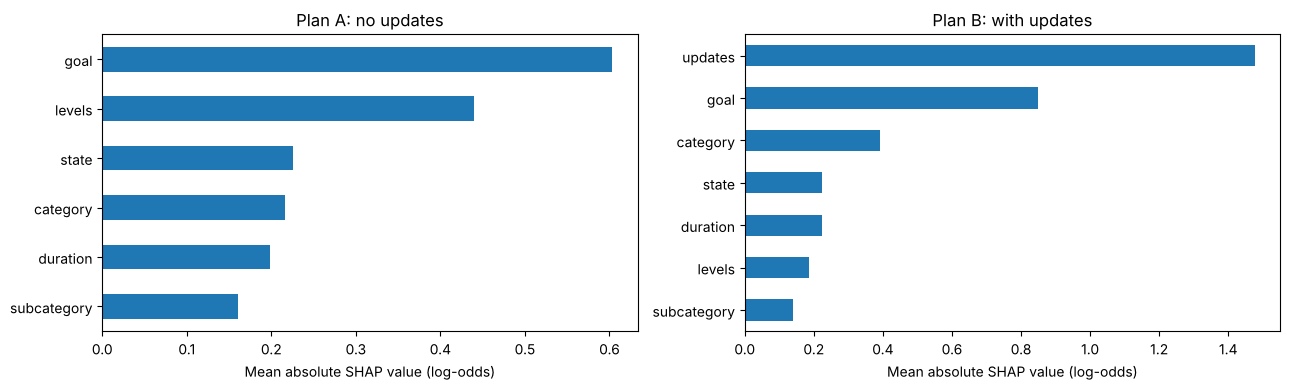

In [5]:
import xgboost

def driver_importance(model, num, n=2000):
    pre, clf = model.named_steps["preprocessor"], model.named_steps["model"]
    sample = test[num + CAT].sample(n, random_state=0)
    Xt = pre.transform(sample)   # keep the data in the same (sparse) form the pipeline gives the model
    names = pre.get_feature_names_out()
    contribs_all = clf.get_booster().predict(xgboost.DMatrix(Xt), pred_contribs=True)

    # Sanity check: contributions (plus the bias column) must add up to the model's own log-odds
    p = model.predict_proba(sample)[:, 1]
    gap = np.abs(contribs_all.sum(axis=1) - np.log(p / (1 - p))).max()
    assert gap < 1e-3, f"SHAP values do not match the model's predictions (gap {gap:.3f})"
    contribs = contribs_all[:, :-1]   # drop the bias column

    def group_of(name):
        if name.startswith("num__"):
            return name[len("num__"):]
        if name.startswith("cat__subcategory_"):
            return "subcategory"
        if name.startswith("cat__category_"):
            return "category"
        return "state"

    groups = np.array([group_of(nm) for nm in names])
    rows = []
    for g in pd.unique(groups):
        g_shap = contribs[:, groups == g].sum(axis=1)
        direction = ""
        if g in num:
            rho = pd.Series(sample[g].values).corr(pd.Series(g_shap), method="spearman")
            direction = ("higher value -> higher chance" if rho > 0.1
                         else "higher value -> lower chance" if rho < -0.1 else "mixed")
        rows.append({"driver": g, "mean_abs_shap": round(float(np.abs(g_shap).mean()), 3), "direction": direction})
    return pd.DataFrame(rows).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)

imp_a = driver_importance(model_a, NUM_A)
imp_b = driver_importance(model_b, NUM_B)
print("Plan A (no updates)");   print(imp_a.to_string(index=False)); print()
print("Plan B (with updates)"); print(imp_b.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (title, imp) in zip(axes, [("Plan A: no updates", imp_a), ("Plan B: with updates", imp_b)]):
    imp.sort_values("mean_abs_shap").plot(kind="barh", x="driver", y="mean_abs_shap", ax=ax, legend=False)
    ax.set_title(title); ax.set_xlabel("Mean absolute SHAP value (log-odds)"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

### From drivers to advice

| Driver | What "improving" it means in practice | How the prototype tests it | Evidence from our EDA | Caveat |
|---|---|---|---|---|
| **Funding goal** | Set a lower goal | Tries 90%, 80%, 67% and 50% of the current goal (never below the 1st percentile of goals) | Success rate falls from about 69% (USD 0-1k) to 49% (USD 5k-10k) and 8% (USD 100k-500k); median goal USD 3,000 for successes vs USD 5,000 for failures | A lower goal also means less money raised; the creator must still be able to fund the project |
| **Campaign duration** | Move toward about 30 days | Tries 20, 30, 45 and 60 days | Campaigns of 45 days or less succeed about 58% of the time, versus about 47% (45-60 days) and 43% (over 60 days) | Evidence is flat below 45 days, so the difference between 20 and 30 days is not established |
| **Reward levels** | Offer more reward tiers (up to about 10) | Tries current + 2, + 4 and + 6 levels, capped at the 90th percentile | Success rises from about 31.5% (0-2 tiers) to 47.0% (3-5) and 56.1% (6-10) | More levels may reflect a better-developed campaign, not cause success |
| **Updates** | Not a lever: used as context for the prediction and shown as an engagement note | Not changed by the recommender | Median 5 updates for successful vs 0 for failed campaigns; correlation 0.39 | Campaigns that are going well post more updates because they are going well |
| **Category, subcategory, state** | Not changed (fixed attributes of the project) | Held fixed | Success rates range from about 33% (Fashion) to 76% (Dance) | Possible extension: suggest a better-fitting subcategory |

The SHAP ranking above shows which of these the model leans on most; the recommender only changes the levers a creator can actually control.

## 5. The recommendation engine

**Levers and the values tried** (kept within realistic ranges seen in the training data):

- **Goal:** 90%, 80%, 67%, and 50% of the current goal (never below the 1st percentile of goals in the data).
- **Campaign length:** 20, 30, 45, or 60 days.
- **Reward levels:** current + 2, + 4, or + 6 (capped at the 90th percentile, to keep suggestions realistic).
- **Updates:** not recommended as a lever (see the note at the top). An optional switch, `suggest_updates=True`, exists only to demonstrate the problem.

Category, subcategory, and state are held fixed, since changing a project's category or location is not a realistic suggestion.

In [6]:
GOAL_FLOOR = train["goal"].quantile(0.01)
LEVELS_CAP = int(train["levels"].quantile(0.90))
UPDATES_CAP = int(train["updates"].quantile(0.99))

def candidate_changes(row, suggest_updates=False):
    """Return a list of (lever, description, {column: new_value}) for one campaign."""
    out = []
    g = float(row["goal"])
    for f in [0.9, 0.8, 0.67, 0.5]:
        new = max(round(g * f, -1) if g >= 100 else round(g * f), GOAL_FLOOR)
        if new < g:
            out.append(("goal", f"Lower the funding goal from {g:,.0f} to {new:,.0f} USD", {"goal": float(new)}))
    for d in [20, 30, 45, 60]:
        if abs(d - float(row["duration"])) >= 1:
            out.append(("duration", f"Set the campaign length to {d} days (currently {row['duration']:.0f})", {"duration": float(d)}))
    for k in [2, 4, 6]:
        new = min(int(row["levels"]) + k, LEVELS_CAP)
        if new > row["levels"]:
            out.append(("levels", f"Offer {new} reward levels (currently {int(row['levels'])})", {"levels": new}))
    if suggest_updates:
        for k in [3, 6, 10]:
            new = min(int(row["updates"]) + k, UPDATES_CAP)
            if new > row["updates"]:
                out.append(("updates", f"Plan about {new} updates (currently {int(row['updates'])})", {"updates": new}))
    return out

def recommend(campaign, model, num_features, suggest_updates=False, top_n=3, min_lift=0.005):
    """campaign: a one-row Series with the model's input columns."""
    cols = num_features + CAT
    base = campaign[cols].to_frame().T.astype({c: float for c in num_features})
    base_p = float(model.predict_proba(base)[:, 1][0])

    cands = candidate_changes(campaign, suggest_updates)
    if not cands:
        return {"current_probability": base_p, "recommendations": [], "combined_probability": base_p}
    rows = []
    for lever, text, change in cands:
        r = base.copy()
        for k, v in change.items():
            r[k] = float(v)
        rows.append(r)
    probs = model.predict_proba(pd.concat(rows, ignore_index=True))[:, 1]

    table = pd.DataFrame({"lever": [c[0] for c in cands], "change": [c[1] for c in cands],
                          "new_values": [c[2] for c in cands], "new_probability": probs})
    table["lift"] = table["new_probability"] - base_p
    best_per_lever = (table.sort_values("lift", ascending=False)
                           .drop_duplicates("lever")
                           .query("lift >= @min_lift")
                           .head(top_n))

    # Apply the best change from each lever together
    combo = base.copy()
    for nv in best_per_lever["new_values"]:
        for k, v in nv.items():
            combo[k] = float(v)
    combined_p = float(model.predict_proba(combo)[:, 1][0]) if len(best_per_lever) else base_p

    return {"current_probability": base_p, "recommendations": best_per_lever, "combined_probability": combined_p}

## 6. Peer benchmark (sanity check)

A recommendation is more convincing if it points toward what successful campaigns in the same area actually look like. This helper reports the typical values for successful campaigns in the same subcategory (or category if the subcategory is small).

In [7]:
def peer_benchmark(campaign, min_n=30):
    peers = train[(train["subcategory"] == campaign["subcategory"]) & (train["success"] == 1)]
    label = campaign["subcategory"]
    if len(peers) < min_n:
        peers = train[(train["category"] == campaign["category"]) & (train["success"] == 1)]
        label = campaign["category"]
    return label, len(peers), peers[["goal", "duration", "levels", "updates"]].median()

## 7. Demo: one campaign, two recommendations

In [8]:
def show_plans(campaign):
    print("=" * 78)
    print(f"Campaign: {campaign['category']} / {campaign['subcategory']} ({campaign['state']})")
    print(f"  Goal {campaign['goal']:,.0f} USD | {campaign['duration']:.0f} days | {int(campaign['levels'])} reward levels | {int(campaign['updates'])} updates")
    print(f"  Actual outcome (from the data): {campaign['status']}")
    for title, model, num, use_u in [("PLAN A - pre-launch advice (no updates)", model_a, NUM_A, False),
                                     ("PLAN B - with updates as context", model_b, NUM_B, False)]:
        res = recommend(campaign, model, num, use_u)
        print(f"\n{title}")
        print(f"  Predicted chance of success today: {res['current_probability']:.0%}  [{risk_level(res['current_probability'])}]")
        if len(res["recommendations"]) == 0:
            print("  No change raised the predicted chance meaningfully.")
            continue
        for i, (_, r) in enumerate(res["recommendations"].iterrows(), 1):
            print(f"  {i}. {r['change']}  ->  {r['new_probability']:.0%} ({r['lift']:+.0%})")
        print(f"  All of the above together (optimistic upper bound): about {res['combined_probability']:.0%}")
    label, n, med = peer_benchmark(campaign)
    print(f"\nTypical SUCCESSFUL campaign in '{label}' (n={n}): goal {med['goal']:,.0f} USD, {med['duration']:.0f} days, {med['levels']:.0f} levels, {med['updates']:.0f} updates")
    print(f"ENGAGEMENT NOTE (association, not a promise): successful peers typically post about {med['updates']:.0f} updates; this campaign has {int(campaign['updates'])}.")

p_a = model_a.predict_proba(test[NUM_A + CAT])[:, 1]
p_b = model_b.predict_proba(test[NUM_B + CAT])[:, 1]
at_risk = test[(p_a < AT_RISK) & (p_b < AT_RISK) & (p_a > 0.25)]   # both models flag the campaign as at risk
demo = at_risk.sample(3, random_state=7)
for _, camp in demo.iterrows():
    show_plans(camp)

Campaign: Film &amp; Video / Documentary (GA)
  Goal 3,500 USD | 45 days | 8 reward levels | 0 updates
  Actual outcome (from the data): failed

PLAN A - pre-launch advice (no updates)
  Predicted chance of success today: 48%  [AT RISK]
  1. Offer 13 reward levels (currently 8)  ->  59% (+11%)
  2. Set the campaign length to 20 days (currently 45)  ->  58% (+10%)
  3. Lower the funding goal from 3,500 to 1,750 USD  ->  57% (+9%)
  All of the above together (optimistic upper bound): about 71%

PLAN B - with updates as context
  Predicted chance of success today: 10%  [HIGH RISK]
  1. Lower the funding goal from 3,500 to 1,750 USD  ->  17% (+7%)
  2. Set the campaign length to 20 days (currently 45)  ->  17% (+7%)
  All of the above together (optimistic upper bound): about 31%

Typical SUCCESSFUL campaign in 'Documentary' (n=1204): goal 6,000 USD, 35 days, 8 levels, 6 updates
ENGAGEMENT NOTE (association, not a promise): successful peers typically post about 6 updates; this campaign has 

## 8. How much do the recommendations help, across many at-risk campaigns?

For a sample of test-set campaigns that each model predicts will fail, find the single best recommended change and measure the predicted lift. This shows which lever matters most and how large the typical effect is.

In [9]:
def summarize(model, num, use_u, n=300):
    p = model.predict_proba(test[num + CAT])[:, 1]
    pool = test[p < AT_RISK]
    sample = pool.sample(min(n, len(pool)), random_state=1)
    rows = []
    for _, camp in sample.iterrows():
        res = recommend(camp, model, num, use_u)
        recs = res["recommendations"]
        if len(recs):
            top = recs.iloc[0]
            rows.append({"top_lever": top["lever"], "top_lift": top["lift"],
                         "combined_lift": res["combined_probability"] - res["current_probability"]})
        else:
            rows.append({"top_lever": "none", "top_lift": 0.0, "combined_lift": 0.0})
    r = pd.DataFrame(rows)
    return r

for name, m, num, use_u in [("Plan A (no updates)", model_a, NUM_A, False), ("Plan B (with updates as context)", model_b, NUM_B, False)]:
    r = summarize(m, num, use_u)
    print(name, f"- sampled {len(r)} campaigns predicted to fail")
    print(f"  Median lift from the best single change: {r['top_lift'].median():+.1%}")
    print(f"  Median lift from combining the best change per lever (optimistic upper bound): {r['combined_lift'].median():+.1%}")
    print("  Which lever was the top suggestion:")
    print((r['top_lever'].value_counts(normalize=True).round(2)).to_string())
    print()

Plan A (no updates) - sampled 300 campaigns predicted to fail
  Median lift from the best single change: +18.8%
  Median lift from combining the best change per lever (optimistic upper bound): +32.3%
  Which lever was the top suggestion:
top_lever
levels      0.67
goal        0.18
duration    0.15



Plan B (with updates as context) - sampled 300 campaigns predicted to fail
  Median lift from the best single change: +10.7%
  Median lift from combining the best change per lever (optimistic upper bound): +21.6%
  Which lever was the top suggestion:
top_lever
goal        0.50
duration    0.39
levels      0.11
none        0.01



## 9. Testing the recommendations on real failed campaigns

Two checks, both using campaigns that **actually failed** in the test set and that both models flag as at risk:

1. **A hand review.** Six campaigns (two each from the lower, middle and higher goal ranges) with both plans' top suggestion, so a person can judge whether the advice is sensible.
2. **A peer-consistency check across many campaigns.** A suggestion is "consistent with peers" if it moves the campaign toward what successful campaigns in the same subcategory typically look like: lowering the goal when the goal is above the peer median, moving the duration closer to the peer median, adding reward levels when the campaign has fewer than the peer median.

In [10]:
pa_all = model_a.predict_proba(test[NUM_A + CAT])[:, 1]
pb_all = model_b.predict_proba(test[NUM_B + CAT])[:, 1]
failed_at_risk = test[(test["success"] == 0) & (pa_all < AT_RISK) & (pb_all < AT_RISK)].copy()
print(f"{len(failed_at_risk)} actual failed campaigns are flagged at risk by both models")

failed_at_risk["goal_range"] = pd.qcut(failed_at_risk["goal"], 3, labels=["lower goals", "middle goals", "higher goals"])
review_set = failed_at_risk.groupby("goal_range", observed=True).sample(2, random_state=11)

def top_rec_text(res):
    r = res["recommendations"]
    return "no change raised the chance meaningfully" if len(r) == 0 else f"{r.iloc[0]['change']} ({r.iloc[0]['lift']:+.0%})"

for n, (idx, camp) in enumerate(review_set.iterrows(), 1):
    ra = recommend(camp, model_a, NUM_A)
    rb = recommend(camp, model_b, NUM_B)
    label, size, med = peer_benchmark(camp)
    print(f"[{n}] {camp['category']} / {camp['subcategory']} ({camp['state']}) | goal {camp['goal']:,.0f} USD, "
          f"{camp['duration']:.0f} days, {int(camp['levels'])} levels, {int(camp['updates'])} updates  (actually {camp['status']})")
    print(f"    Plan A: {ra['current_probability']:.0%} [{risk_level(ra['current_probability'])}] -> {top_rec_text(ra)}")
    print(f"    Plan B: {rb['current_probability']:.0%} [{risk_level(rb['current_probability'])}] -> {top_rec_text(rb)}")
    print(f"    Typical successful peer in '{label}': goal {med['goal']:,.0f} USD, {med['duration']:.0f} days, {med['levels']:.0f} levels, {med['updates']:.0f} updates\n")

1858 actual failed campaigns are flagged at risk by both models
[1] Publishing / Children's Book (MA) | goal 3,300 USD, 60 days, 6 levels, 0 updates  (actually failed)
    Plan A: 38% [AT RISK] -> Offer 12 reward levels (currently 6) (+19%)
    Plan B: 4% [HIGH RISK] -> Set the campaign length to 20 days (currently 60) (+4%)
    Typical successful peer in 'Children's Book': goal 3,288 USD, 30 days, 8 levels, 7 updates

[2] Art / Performance Art (FL) | goal 1,600 USD, 60 days, 1 levels, 0 updates  (actually failed)
    Plan A: 24% [HIGH RISK] -> Offer 7 reward levels (currently 1) (+26%)
    Plan B: 14% [HIGH RISK] -> Set the campaign length to 20 days (currently 60) (+16%)
    Typical successful peer in 'Performance Art': goal 2,000 USD, 30 days, 6 levels, 2 updates

[3] Food / Food (NJ) | goal 10,000 USD, 31 days, 4 levels, 0 updates  (actually failed)
    Plan A: 19% [HIGH RISK] -> Offer 10 reward levels (currently 4) (+38%)
    Plan B: 5% [HIGH RISK] -> Lower the funding goal from 1

[4] Design / Graphic Design (TX) | goal 6,000 USD, 30 days, 5 levels, 0 updates  (actually failed)
    Plan A: 32% [AT RISK] -> Offer 11 reward levels (currently 5) (+29%)
    Plan B: 4% [HIGH RISK] -> Set the campaign length to 20 days (currently 30) (+4%)
    Typical successful peer in 'Graphic Design': goal 1,500 USD, 30 days, 6 levels, 6 updates



[5] Music / Country &amp; Folk (TN) | goal 22,000 USD, 60 days, 9 levels, 4 updates  (actually failed)
    Plan A: 25% [HIGH RISK] -> Lower the funding goal from 22,000 to 11,000 USD (+32%)
    Plan B: 43% [AT RISK] -> Lower the funding goal from 22,000 to 11,000 USD (+22%)
    Typical successful peer in 'Country &amp; Folk': goal 3,000 USD, 31 days, 9 levels, 5 updates

[6] Film &amp; Video / Narrative Film (CA) | goal 39,000 USD, 30 days, 8 levels, 0 updates  (actually failed)
    Plan A: 19% [HIGH RISK] -> Offer 13 reward levels (currently 8) (+22%)
    Plan B: 1% [HIGH RISK] -> Lower the funding goal from 39,000 to 19,500 USD (+3%)
    Typical successful peer in 'Narrative Film': goal 5,000 USD, 31 days, 9 levels, 5 updates



In [11]:
def consistent_with_peers(campaign, lever, new_values):
    _, _, med = peer_benchmark(campaign)
    if lever == "goal":
        return bool(campaign["goal"] > med["goal"])
    if lever == "duration":
        return bool(abs(new_values["duration"] - med["duration"]) < abs(campaign["duration"] - med["duration"]))
    if lever == "levels":
        return bool(campaign["levels"] < med["levels"])
    return None

check_sample = failed_at_risk.sample(min(200, len(failed_at_risk)), random_state=3)
for name, model, num in [("Plan A (no updates)", model_a, NUM_A), ("Plan B (with updates)", model_b, NUM_B)]:
    rows = []
    for _, camp in check_sample.iterrows():
        recs = recommend(camp, model, num)["recommendations"]
        if len(recs):
            top = recs.iloc[0]
            rows.append({"lever": top["lever"], "consistent": consistent_with_peers(camp, top["lever"], top["new_values"])})
    r = pd.DataFrame(rows)
    print(f"{name}: top suggestion consistent with successful peers in {r['consistent'].mean():.0%} of {len(r)} failed campaigns")
    print((r.groupby("lever")["consistent"].agg(share_consistent="mean", campaigns="size").round(2)).to_string())
    print()

Plan A (no updates): top suggestion consistent with successful peers in 90% of 200 failed campaigns
          share_consistent  campaigns
lever                                
duration              0.96         27
goal                  1.00         43
levels                0.85        130



Plan B (with updates): top suggestion consistent with successful peers in 89% of 196 failed campaigns
          share_consistent  campaigns
lever                                
duration              0.81         57
goal                  0.91        110
levels                0.97         29



### Review notes

### Review notes

*Reading the six failed campaigns above, the recommendations were mostly sensible, with a few clear weak spots.*

- **Campaign 1 (Children's Book, MA):** Sensible. The goal (USD 3,300) matches successful peers (about USD 3,288), so no goal advice is right. It runs 60 days against a peer median of 30, has 6 reward levels against 8, and posted no updates against about 7. Plan A suggests more reward levels, and Plan B suggests a 20-day campaign. Both point toward the peers, but 12 levels is more than the peer median of 8, so the size of that suggestion is aggressive.
- **Campaign 2 (Performance Art, FL):** Sensible. The goal (USD 1,600) is already below the peer median, and the recommender correctly does not suggest changing it. It has 1 reward level against about 6 for peers, so adding levels (+26 points in Plan A) makes sense, and Plan B's 20-day suggestion fits a 60-day campaign.
- **Campaign 3 (Food, NJ):** Mostly sensible. The goal (USD 10,000) is double the peer median of USD 5,000, and Plan B lowers it to exactly USD 5,000. Plan A prefers adding 6 reward levels (+38 points), which is plausible since the campaign has 4 against about 8, but the goal gap is also a clear issue. Neither plan changes the 31-day length, which is correct since it already matches peers.
- **Campaign 4 (Graphic Design, TX):** Weakest example. The goal (USD 6,000) is about four times the peer median (USD 1,500), yet Plan A leads with adding reward levels. Plan B suggests shortening a 30-day campaign to 20 days for only +4 points, even though 30 days already matches the peers and our duration analysis found no clear difference below 45 days. Both suggestions look arbitrary here.
- **Campaign 5 (Country & Folk, TN):** Best example. The goal (USD 22,000) is about seven times the peer median (USD 3,000), while the length, reward levels and updates are all close to peers. Both plans put "lower the goal" first (+32 points in Plan A, +22 in Plan B), which is exactly the right advice. Even halving the goal leaves it well above what successful peers typically ask for.
- **Campaign 6 (Narrative Film, CA):** Mixed. The goal (USD 39,000) is about eight times the peer median (USD 5,000). Plan B correctly suggests lowering it, but the lift is only 3 points, because the campaign has no updates and a 1% predicted chance, which no change to goal, length or reward levels can fix. Plan A suggests adding reward levels first, which ignores the much bigger goal gap.

**Overall:** The advice is sensible when one feature is a clear outlier (campaigns 2 and 5). It looks weaker when the top suggestion is chosen purely by predicted lift and ignores a very large goal gap (campaigns 4 and 6 in Plan A) or suggests changing a length that already matches peers (campaign 4 in Plan B). For campaigns with no updates, Plan B's best change often adds only a few points, so the engagement gap is the real problem and no lever can close it.

## 10. Limitations and next steps

- **Association, not causation.** Recommendations come from patterns in historical data. A lower goal, a different length or more reward levels is associated with a higher predicted chance of success; this prototype cannot prove it would change an individual campaign's outcome. SHAP shows what the model relies on, not what causes success.
- **Updates.** Updates may partly be a *result* of a campaign doing well. When we allowed the model to recommend more updates, it dominated everything with implausibly large lifts, so updates are used only as context and a labeled engagement note.
- **The at-risk definition is a choice.** The 0.5 and 0.3 cutoffs are defaults; a different cutoff changes how many failures are caught versus how many false alarms are raised (Section 3).
- **Ranking by predicted lift has blind spots.** In the review above, Plan A often puts reward levels first even when the funding goal is many times the typical successful goal in the subcategory (for example a USD 39,000 goal against a USD 5,000 peer median), because adding levels produces the largest predicted lift. A reasonable improvement is to show the goal suggestion alongside it whenever the goal is far above the peer median.
- **Some at-risk campaigns cannot be rescued with these levers.** When a campaign has no updates, Plan B's best change often adds only 3-4 points: the model's pessimism comes from low engagement, which goal, length and reward levels do not fix. The engagement note is the honest message in those cases.
- **Peer consistency is a plausibility check, not validation.** It shows that advice points toward what successful campaigns look like, not that following it would lead to success.
- **Combined estimates are optimistic.** The "all together" number assumes each change's effect adds up and that the model extrapolates well; treat it as an upper bound.
- **One lever at a time.** Single-lever changes are scored independently.
- **Fixed attributes.** Category, subcategory and state are not changed. A natural extension is to suggest a better-fitting subcategory.
- **Data quirk.** Some category labels appear under two spellings (for example `Film & Video` and `Film &amp; Video`), which the model treats as different categories. Cleaning them with `html.unescape` and rerunning would be a small improvement.
- **Possible next steps:** a lower decision threshold or class weights to catch more failed campaigns, and a small interactive demo (for example Streamlit) wrapping `recommend()`.